# Primera prueba: anticipar crecimiento poblacional con censos

Proyecto individual tutorado con Pablo Valenzuela. Clasificación supervisada temporal, usando datos oficiales del INE. **El resultado de esta prueba fue negativo frente a la continuidad de tendencia.** Se documenta el proceso sin ajustar el experimento con la prueba final.

## 1. Pregunta, unidad y respuesta

¿Podemos clasificar si una comuna tendrá un crecimiento medio de al menos 1% anual usando población y estructura por edades del censo inicial? Cada ejemplo es una **comuna en un período**, no un habitante. El umbral es una decisión del proyecto, no una categoría oficial. La tasa es `(P_final/P_inicial)**(1/años)-1`.

Entrenamiento: 1992→2002. Validación: 2002→2017. Prueba: 2017→2024. Las mismas comunas se repiten porque se evalúa cambio temporal, no comunas desconocidas. Esta es una reconstrucción retrospectiva, no un pronóstico emitido en 2017.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import sklearn
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'experiments').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'experiments'))
import crecimiento_censal as study
OUT = ROOT / 'results/crecimiento_censal'
print('Python:', sys.version.split()[0], 'scikit-learn:', sklearn.__version__)
REGENERAR = False
if REGENERAR: study.run()
protocol = json.loads((ROOT / 'experiments/protocolo_crecimiento.json').read_text())
summary = json.loads((OUT / 'resumen.json').read_text())
quality = json.loads((OUT / 'calidad_datos.json').read_text())
profiles = pd.read_csv(OUT / 'perfiles_censales.csv')

Python: 3.12.14 scikit-learn: 1.7.2


## 2. Procedencia y preparación

Se consultaron tabulados agregados de los censos 1992, 2002 y 2017 mediante REDATAM del INE. Se conservan HTML crudos, parámetros de consulta y hashes. En 1992 y 2002 se usa comuna de residencia habitual (`VIVEHAB`), no solo lugar de empadronamiento. En 2017 se suman quienes viven en la comuna donde fueron censados (`P10=1 o 2`, tabulados por comuna) y quienes fueron censados en otra comuna (tabulado por `P10COMUNA`). Los códigos sin comuna identificada quedan fuera, sin imputar residencia.

La composición etaria utiliza la misma definición de menores de 15 y 65 o más. Las variantes ortográficas se resuelven mediante equivalencias explícitas. No se emparejan automáticamente nombres parecidos. Se excluyen cambios territoriales conocidos e identidades ambiguas. **Todavía falta certificar todos los límites con cartografías históricas.**

In [2]:
sources = json.loads((ROOT / 'data/raw/ine/crecimiento/fuentes.json').read_text())
display(pd.DataFrame([{k:r.get(k) for k in ('file','url','bytes','sha256')} for r in sources['files']]))
print('Contraste independiente de 2017:', quality['independent_2017_check'])
print('Comunas incluidas:', quality['included_communes'], 'excluidas:', len(quality['exclusions']))
display(pd.DataFrame(quality['exclusions'])[['name','reason']])

,file,url,bytes,sha256
0,edad_residencia_1992.html,https://redatam-ine.ine.cl/redbin/RpWebStats.e...,397439,a6dd2b414fb0466bec4519d698d56216e40dd1ebb6fc3a...
1,edad_residencia_2002.html,https://redatam-ine.ine.cl/redbin/RpWebStats.e...,347336,24212f5052fd331bd7135846af70c1847482e48a9f9d82...
2,edad_residencia_2017.html,https://redatam-ine.ine.cl/redbin/RpWebStats.e...,306826,efa35d98f0ee8522f809f9d19638d75e59b3b354a44c3d...
3,edad_local_2017.html,https://redatam-ine.ine.cl/redbin/RpWebStats.e...,262995,996b8f65fac8ed7a81862c81459f768af0d3c9686d4447...
4,poblacion_2024.xlsx,https://censo2024.ine.gob.cl/wp-content/upload...,505437,1f3a9c97a1b3defa47a2fc3b8495688c4e08f164063cab...
5,residentes_2017.xlsx,https://censo2024.ine.gob.cl/wp-content/upload...,69970,ea5aa0f3a1bad6acce93252e7f1e590f11dd721d1331eb...


Contraste independiente de 2017: {'compared_communes': 346, 'differences': []}
Comunas incluidas: 314 excluidas: 32


,name,reason
0,Iquique,Creación de comunas en 2004 y sus comunas de o...
1,Alto Hospicio,Creación de comunas en 2004 y sus comunas de o...
2,Caldera,Dos etiquetas Caldera en REDATAM 1992; no corr...
3,Paihuano,Cambio de límite de Ley 20.721 (2014)
4,Vicuña,Cambio de límite de Ley 20.721 (2014)
5,Combarbalá,Cambios de límites de Ley 20.578 (2012)
6,Punitaqui,Cambios de límites de Ley 20.578 (2012)
7,Concón,Creación o división comunal 1994–1996; geograf...
8,Viña del Mar,Creación o división comunal 1994–1996; geograf...
9,Calera,Dos etiquetas Caldera en REDATAM 1992; no corr...


## 3. Exploración y tipos de variables

Población: recuento discreto, escala de razón. Proporciones por edad: variables numéricas de razón. Código y nombre comunal: identificadores nominales, excluidos del modelo. Año identifica la etapa, también se excluye como entrada. La clase objetivo es binaria. No se requieren imputación ni escalado ajustado sobre toda la base: se usan perfiles completos y tres entradas numéricas.

In [3]:
display(profiles.groupby('year').agg(comunas=('code','nunique'), residentes=('population','sum'), menores_15=('young','sum'), personas_65_mas=('old','sum')))
display(pd.DataFrame([{'etapa':stage,'menor_1_por_ciento':values['class_counts'][0],'al_menos_1_por_ciento':values['class_counts'][1]} for stage,values in [('entrenamiento',summary['train']),('validacion',summary['validation'][summary['selected']]),('prueba',summary['test']['modelo'])]]))
display(profiles[['population','young','old']].describe())

,comunas,residentes,menores_15,personas_65_mas
year,,,,
1992,314,10973966,3217735,737588
2002,314,12193480,3127773,1014922
2017,314,13996011,2787093,1632812
2024,314,14966943,2642359,2121840


,etapa,menor_1_por_ciento,al_menos_1_por_ciento
0,entrenamiento,190,124
1,validacion,217,97
2,prueba,164,150


,population,young,old
count,1256.000000,1256.000000,1256.000000
mean,41505.095541,9374.968153,4384.683121
std,64368.904747,13977.856023,7072.848086
min,27.000000,0.000000,0.000000
25%,8179.750000,1803.750000,857.750000
50%,16432.500000,3897.000000,1805.000000
75%,39271.000000,9478.250000,4273.000000
max,517384.000000,128232.000000,71127.000000


## 4. Separación temporal y prevención de filtración

X contiene `log(1+población_inicial)`, proporción de menores de 15 y proporción de 65 o más del inicio. La población final solo construye y; no se entrega al clasificador. Un aumento de habitantes dentro del mismo período no es una variable predictora. No se divide aleatoriamente una tabla que mezcle todos los años.

La configuración se eligió usando 314 ejemplos de entrenamiento y 314 de validación. Después se reentrenó solo la elegida con esos 628 ejemplos. La elección, los parámetros y las métricas de validación se guardaron **antes de leer las cifras finales de 2024**. Las tablas fueron descargadas previamente, pero no se calcularon las etiquetas de prueba para elegir. Los datos censales son observaciones de cada período; se utiliza su publicación actual para este ejercicio retrospectivo.

In [4]:
historical = profiles.loc[profiles.year < 2024]
initial_train, X_train, y_train, _ = study.interval(historical,1992,2002)
initial_val, X_val, y_val, _ = study.interval(historical,2002,2017)
assert list(X_train.columns) == protocol['features']
assert all('population_final' not in c for c in X_train.columns)
assert np.isfinite(X_train.to_numpy()).all()
print('X de entrenamiento:',X_train.shape,'y:',y_train.shape)
display(X_train.head())
display(pd.DataFrame(protocol['alternatives']))

X de entrenamiento: (314, 3) y: (314,)


,log_poblacion,proporcion_menores_15,proporcion_65_mas
code,,,
1401,8.733916,0.346755,0.063778
1402,7.259116,0.396479,0.062676
1403,7.349231,0.442085,0.063707
1404,7.566311,0.300880,0.129984
1405,7.754910,0.296312,0.105918


,id,algorithm,params
0,arbol,DecisionTreeClassifier,"{'max_depth': 3, 'min_samples_leaf': 15, 'clas..."
1,bosque,RandomForestClassifier,"{'n_estimators': 300, 'max_depth': 5, 'min_sam..."


## 5. Entrenamiento y selección

Se comparan un árbol limitado a profundidad 3 y un bosque de 300 árboles limitado a profundidad 5. Los tamaños mínimos de hoja limitan el sobreajuste y se ponderan clases. Se selecciona por F1 macro de validación, con exactitud balanceada y simplicidad como desempates.

Referencias: clase mayoritaria del entrenamiento y continuidad de la clase de crecimiento del intervalo anterior. La continuidad dispone de una tasa histórica adicional, que los clasificadores de esta versión no reciben como entrada. Es información disponible al inicio y una referencia práctica exigente. Esta diferencia limita cualquier conclusión general sobre los algoritmos.

In [5]:
models = study.make_models(protocol)
comparisons = []
for name, classifier in models.items():
    classifier.fit(X_train,y_train)
    observed = study.metrics(y_val,classifier.predict(X_val))
    assert np.isclose(observed['f1_macro'],summary['validation'][name]['f1_macro'])
    comparisons.append({'alternativa':name,'F1_macro_validacion':observed['f1_macro'],'exactitud_balanceada':observed['balanced_accuracy'],'exactitud':observed['accuracy']})
display(pd.DataFrame(comparisons))
closed = json.loads((OUT / 'seleccion_cerrada.json').read_text())
print('Elección cerrada:',closed['selected'],'prueba usada para elegir:',closed['test_used_for_selection'])

,alternativa,F1_macro_validacion,exactitud_balanceada,exactitud
0,arbol,0.483258,0.493539,0.512739
1,bosque,0.550787,0.551618,0.656051


Elección cerrada: bosque prueba usada para elegir: False


## 6. Prueba final y errores

2024 aporta el resultado observado posterior a las entradas de 2017. La elección sigue siendo la de validación, aunque una referencia resulte mejor en prueba. No se modificaron variables, umbral ni parámetros para elevar las métricas de 2024. F1 macro da el mismo peso a las dos clases. La matriz muestra filas reales y columnas predichas.

,alternativa,n,f1_macro,balanced_accuracy,accuracy
0,modelo,314,0.527633,0.532602,0.538217
1,mayoria,314,0.343096,0.500000,0.522293
2,persistencia,314,0.663001,0.670163,0.678344


,Predice <1%,Predice ≥1%
Real <1%,108,56
Real ≥1%,89,61


,precision,recall,f1-score,support
Menor que 1% anual,0.548223,0.658537,0.598338,164.000000
Al menos 1% anual,0.521368,0.406667,0.456929,150.000000
accuracy,0.538217,0.538217,0.538217,0.538217
macro avg,0.534795,0.532602,0.527633,314.000000
weighted avg,0.535394,0.538217,0.530786,314.000000


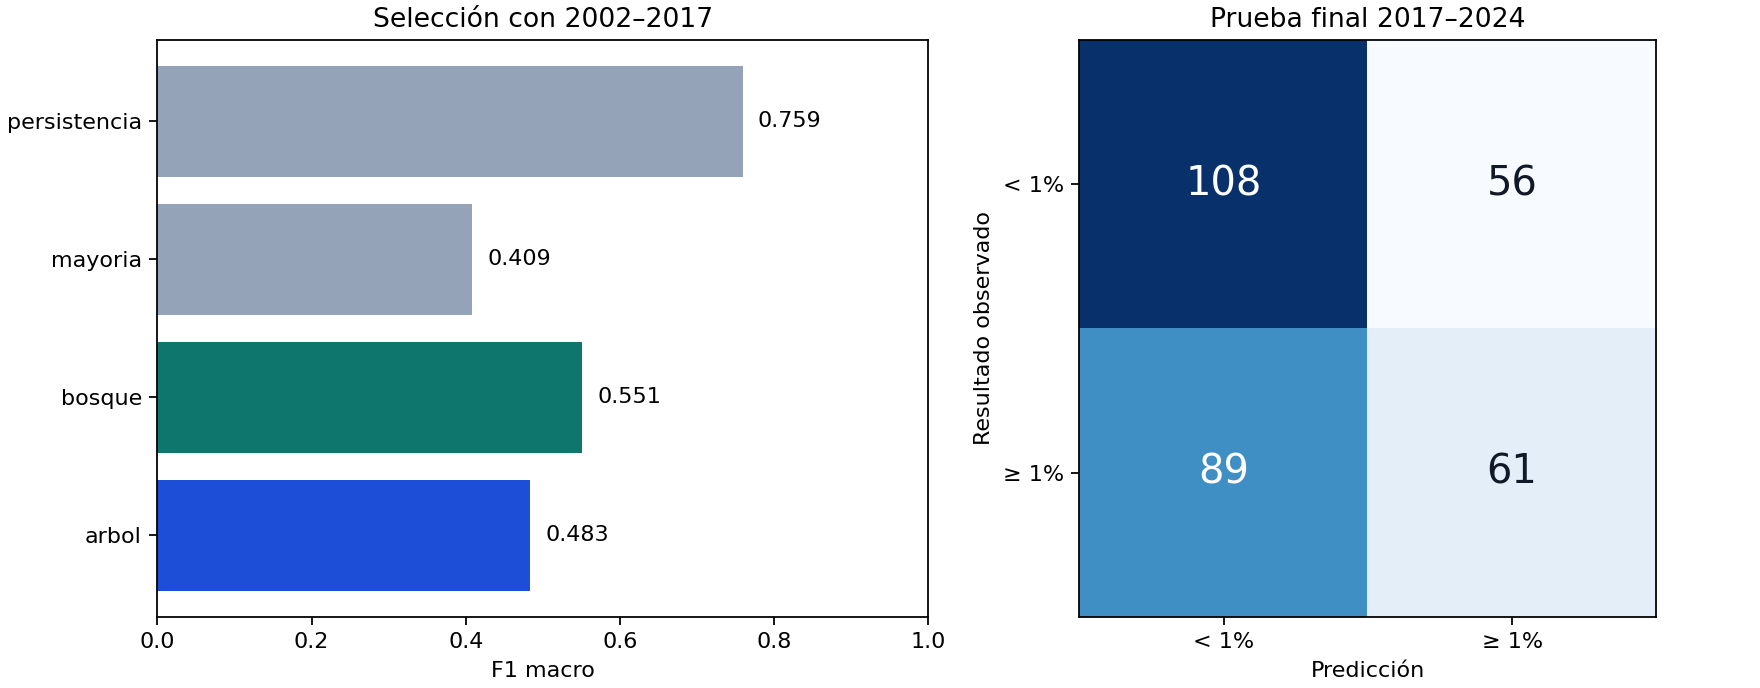

,name,population,actual_population,predicted_class,actual_class,actual_rate,correct
0,Pozo Almonte,13942,16878,0,1,0.027677,False
1,Camiña,1217,1335,0,1,0.013308,False
2,Colchane,1232,790,1,0,-0.061507,False
3,Huara,2533,2858,0,1,0.017395,False
4,Pica,4805,6272,0,1,0.038796,False
5,Antofagasta,356427,401096,0,1,0.017010,False
6,Mejillones,12061,14084,0,1,0.022399,False
7,Sierra Gorda,1491,1472,0,0,-0.001830,True


In [6]:
display(pd.DataFrame([{'alternativa':name,**{k:v[k] for k in ('n','f1_macro','balanced_accuracy','accuracy')}} for name,v in summary['test'].items()]))
display(pd.DataFrame(summary['test']['modelo']['confusion'],index=['Real <1%','Real ≥1%'],columns=['Predice <1%','Predice ≥1%']))
display(pd.DataFrame(summary['test']['modelo']['classes']).T)
display(Image(filename=str(OUT / 'evaluacion.png')))
predictions = pd.read_csv(OUT / 'predicciones_prueba.csv')
display(predictions[['name','population','actual_population','predicted_class','actual_class','actual_rate','correct']].head(8))

## 7. Resultado, utilidad y límites

El bosque fue la mejor alternativa entrenada según validación. En prueba final obtuvo **F1 macro 0,528** y **169 aciertos de 314**. La continuidad de tendencia obtuvo **0,663** y **213 de 314**. Esta versión no aporta mejora frente a esa referencia. Ese resultado es parte del experimento, no se oculta.

El prototipo permite consultar una comuna, ver las tres entradas, obtener la clasificación y revelar el resultado real. Incluye un escenario 2024→2031 expresamente experimental, sin resultado observado y sin validación futura. Usa el mismo modelo entrenado antes de la prueba: no se reutilizan las etiquetas de 2024 para reentrenarlo. El score interno no es una probabilidad calibrada.

Una futura versión podría incorporar crecimiento anterior, más períodos y otras variables pertinentes. Se debe registrar un nuevo protocolo y una nueva estrategia de evaluación: **la prueba de 2024 ya fue observada y no volvería a ser una prueba final intacta**. Pocos intervalos, diferencias de duración, no respuesta, cambios de cobertura y geografía limitan la inferencia. La aprobación académica y el calendario individual deben acordarse con Pablo Valenzuela.

## Fuentes

- [INE, censos y REDATAM](https://www.ine.gob.cl/estadisticas-por-tema/demografia-y-poblacion/censo-de-poblacion-y-vivienda).
- [Tablas Censo 2024](https://censo2024.ine.gob.cl/resultados/).
- [Comparación de población censada y residente](https://censo2024.ine.gob.cl/wp-content/uploads/2025/04/N3_Nota_Tecnica_Comparacion_Poblacion_CPV2024.pdf).
- [Ley 20.578, cambios de límites](https://www.bcn.cl/leychile/navegar?idNorma=1038291).
- [Ley 20.721, Vicuña y Paihuano](https://www.bcn.cl/leychile/navegar?idNorma=1058812).

Atribución: INE, Censos de Población y Vivienda. Tabulados y derivados bajo CC BY-SA 4.0, con cambios documentados. No se utilizan proyecciones como observaciones, ni registros privados de CliniPets.